# Computação quântica 2 — Portas, medidas e emaranhamento com o Q-BASIC

No primeiro tutorial construímos um simulador de qubits com NumPy. Aqui fazemos o mesmo com a
biblioteca `qbasic`, que já traz os estados, as portas lógicas, a simulação de medidas e ferramentas
para estudar o emaranhamento.

Convenção: o qubit 0 é o da **esquerda**: `ket("01")` $= |0\rangle \otimes |1\rangle$.

Para rodar: `pip install "Q-BASIC[plot]"`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import qbasic as qb

## 1. Qubits e a esfera de Bloch

Um qubit $|\psi\rangle = \cos(\theta/2)|0\rangle + e^{i\phi}\sin(\theta/2)|1\rangle$ corresponde a um
ponto da esfera de Bloch, com coordenadas $(\langle X\rangle, \langle Y\rangle, \langle Z\rangle)$.

|0> [0. 0. 1.]
|+> [1. 0. 0.]
|+i> [0. 1. 0.]


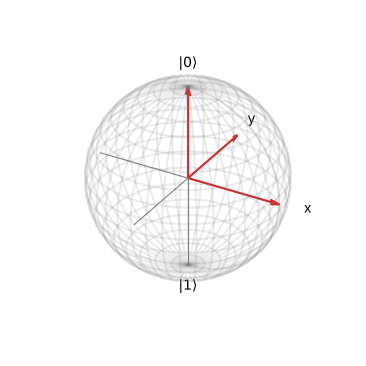

In [2]:
zero = qb.ket("0")
mais = qb.hadamard() * zero  # (|0> + |1>)/√2
mais_i = qb.porta_s() * mais  # (|0> + i|1>)/√2

for nome, estado in [("|0>", zero), ("|+>", mais), ("|+i>", mais_i)]:
    print(nome, qb.vetor_bloch(estado).round(3))

qb.esfera_bloch([zero, mais, mais_i]);

As rotações $R_x$, $R_y$ e $R_z$ giram o vetor de Bloch. Aplicando $R_y(\theta)$ com $\theta$ crescente
ao estado $|0\rangle$, o vetor desce do polo norte até o polo sul:

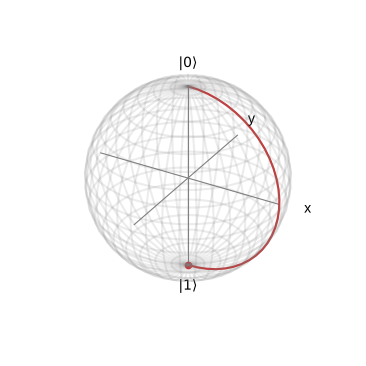

In [3]:
trajetoria = [qb.vetor_bloch(qb.ry(theta) * zero) for theta in np.linspace(0, np.pi, 30)]
qb.esfera_bloch(trajetoria, trajetoria=True);

## 2. Medidas

Medir na base computacional dá o resultado $k$ com probabilidade $|\langle k|\psi\rangle|^2$.
`qb.probabilidades` calcula essas probabilidades e `qb.amostrar` **simula** as medidas, como num
computador quântico real (com uma semente, para o resultado ser reprodutível):

probabilidades: [0.75 0.25]
contagens: {'0': 772, '1': 228}


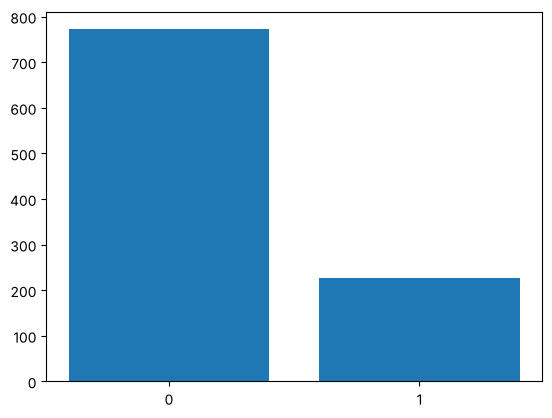

In [4]:
psi = qb.ry(np.pi / 3) * zero
print("probabilidades:", qb.probabilidades(psi).round(3))
contagens = qb.amostrar(psi, n_amostras=1000, semente=42)
print("contagens:", contagens)
plt.bar(list(contagens), list(contagens.values()));

## 3. O circuito de Bell

O circuito mais famoso: uma Hadamard no qubit 0 seguida de uma CNOT (controle 0, alvo 1) transforma
$|00\rangle$ no estado de Bell $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt{2}$.

In [5]:
circuito = qb.cnot(controle=0, alvo=1) * qb.tensor(qb.hadamard(), qb.identidade(2))
bell = circuito * qb.ket("00")
print("fidelidade com |Φ+>:", round(qb.fidelidade(bell, qb.bell("phi+")), 6))
qb.cnot()

fidelidade com |Φ+>: 1.0


ObjQuantico: tipo=operador, dim=4, shape=(4, 4), formato=denso, dims=[[2, 2], [2, 2]]
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]]

Medindo os dois qubits, só aparecem `00` e `11`: os resultados são perfeitamente correlacionados,
embora cada qubit, sozinho, dê 0 ou 1 com 50% de chance.

In [6]:
print(qb.amostrar(bell, 1000, semente=7))
ZZ = qb.tensor(qb.pauliZ(), qb.pauliZ())
print("correlação <Z⊗Z> =", qb.valor_esperado(bell, ZZ))
print("<Z> do qubit 0   =", qb.valor_esperado(bell, qb.porta_em(qb.pauliZ(), 0, 2)))

{'00': 500, '11': 500}
correlação <Z⊗Z> = 0.9999999999999998
<Z> do qubit 0   = 0.0


## 4. Medindo o emaranhamento

O estado de **um** qubit de um par emaranhado é obtido com o **traço parcial**. Para o par de Bell ele é
o estado maximamente misturado $I/2$: pureza $1/2$ e entropia de von Neumann de 1 bit (o máximo para um
qubit). Para um estado produto, a entropia é zero.

In [7]:
for nome, estado in [("Bell", bell), ("produto |+>|0>", qb.tensor(mais, zero)), ("GHZ (3 qubits)", qb.ghz(3)), ("W (3 qubits)", qb.w(3))]:
    rho_0 = qb.traco_parcial(estado, 0)
    print(f"{nome:16s} pureza do qubit 0 = {qb.pureza(rho_0):.3f}   entropia = {qb.entropia_von_neumann(rho_0):.3f} bit")

Bell             pureza do qubit 0 = 0.500   entropia = 1.000 bit
produto |+>|0>   pureza do qubit 0 = 1.000   entropia = 0.000 bit
GHZ (3 qubits)   pureza do qubit 0 = 0.500   entropia = 1.000 bit
W (3 qubits)     pureza do qubit 0 = 0.556   entropia = 0.918 bit


## 5. Teleportação quântica

Alice quer enviar a Bob um estado desconhecido $|\psi\rangle$ (qubit 0), usando um par de Bell
compartilhado (qubits 1 e 2) e dois bits clássicos. No circuito abaixo, as correções que Bob faria
depois de receber os bits são feitas por portas controladas (o "princípio da medida adiada"), o que
dá o mesmo resultado.

In [8]:
psi = (qb.rz(0.7) * qb.ry(1.1) * zero).normalizar()  # estado "desconhecido"

estado = qb.tensor(psi, qb.bell("phi+"))  # qubit 0: Alice; qubits 1 e 2: par de Bell
estado = qb.cnot(0, 1, n_qubits=3) * estado
estado = qb.porta_em(qb.hadamard(), 0, 3) * estado
estado = qb.cnot(1, 2, n_qubits=3) * estado  # correção X de Bob
estado = qb.cz(0, 2, n_qubits=3) * estado  # correção Z de Bob

qubit_de_bob = qb.traco_parcial(estado, 2)
print("fidelidade do estado de Bob com |ψ>:", round(qb.fidelidade(qubit_de_bob, psi), 10))

fidelidade do estado de Bob com |ψ>: 1.0


O estado chegou intacto ao qubit 2, embora nenhum qubit tenha "viajado" de Alice até Bob.

## Resumo das ferramentas

| Tarefa | Função |
|---|---|
| estados | `qb.ket("0110")`, `qb.bell(...)`, `qb.ghz(n)`, `qb.w(n)` |
| portas de 1 qubit | `qb.pauliX()`, `qb.hadamard()`, `qb.porta_s()`, `qb.porta_t()`, `qb.rx/ry/rz(θ)` |
| portas de vários qubits | `qb.cnot`, `qb.cz`, `qb.swap`, `qb.toffoli`, `qb.porta_controlada`, `qb.porta_em` |
| medidas | `qb.probabilidades`, `qb.amostrar`, `qb.valor_esperado` |
| emaranhamento | `qb.traco_parcial`, `qb.pureza`, `qb.entropia_von_neumann`, `qb.fidelidade` |
| visualização | `qb.vetor_bloch`, `qb.esfera_bloch` |